# Tutorial para iniciantes: Data Wrangling e Visualização de Dados

**Autor:** Fabio Stein

Neste tutorial você vai pegar uma tabela **suja** (com valores nulos, valores impossíveis, texto bagunçado e linhas duplicadas), limpar passo a passo e depois fazer gráficos.

**Como usar:** execute uma célula por vez (`Shift + Enter`), leia a explicação antes e olhe o resultado depois. Não pule etapas.

| Parte | Assunto |
|---|---|
| 0 | Preparar o ambiente |
| 1 | Criar e carregar os dados sujos |
| 2 | Primeira olhada nos dados |
| 3 | Valores nulos (incluindo os "disfarçados") |
| 4 | Valores impossíveis |
| 5 | Texto bagunçado e duplicados |
| 6 | Tratar os nulos: apagar ou preencher? |
| 7 | Validar a limpeza |
| 8 | Visualização de dados |
| 9 | Exercícios |

## Conceitos fundamentais (leia antes de começar)

### O que é *Data Wrangling*?
*Data wrangling* (ou *data munging*) é o processo de **transformar dados brutos em dados confiáveis e prontos para análise**. Kandel et al. [7] mostraram que analistas gastam a maior parte do tempo nessa etapa, e não na modelagem. No modelo **CRISP-DM** [18], que é a metodologia mais usada em projetos de dados, essa fase se chama *Data Preparation* e vem logo depois de *Data Understanding* (entender os dados). Este tutorial segue exatamente essa ordem: primeiro **entender**, depois **preparar**.

### O que são dados "sujos"? As dimensões da qualidade de dados
Wang & Strong [6] definiram que um dado tem qualidade quando é adequado ao uso. As dimensões que mais vamos trabalhar:

| Dimensão | Pergunta | Problema no nosso dataset | Parte |
|---|---|---|---|
| **Completude** | Falta informação? | valores nulos e nulos disfarçados | 3 e 6 |
| **Validade** | O valor respeita as regras do mundo real? | idade -3, nota 15 | 4 |
| **Consistência** | A mesma coisa é escrita do mesmo jeito? | "SP" × "São Paulo" | 5 |
| **Unicidade** | Cada entidade aparece uma vez só? | alunos duplicados | 5 |

### Tidy Data (dados organizados)
Hadley Wickham [1] propôs três regras para uma tabela "arrumada":
1. Cada **variável** é uma **coluna**.
2. Cada **observação** é uma **linha**.
3. Cada **valor** fica em uma **célula**.

Nossa tabela já segue essas regras (cada linha é um aluno, cada coluna uma característica). Isso importa porque o pandas e o seaborn são feitos para trabalhar com dados *tidy*.

### Como as referências funcionam
Os números entre colchetes, como **[1]**, apontam para a lista de **Referências** no final. Os quadros **📚 Teoria** explicam o conceito por trás de cada passo, e os quadros **🔍 Passo a passo** explicam o código linha a linha.

## Parte 0: Preparar o ambiente

Se ainda não tem as bibliotecas instaladas, rode no terminal:

```
pip install numpy pandas matplotlib seaborn jupyter
```

Agora importamos as bibliotecas. Os apelidos (`np`, `pd`, `plt`, `sns`) são convenção, todo mundo usa.

### 📚 Teoria: o ecossistema científico do Python
| Biblioteca | Papel | Referência |
|---|---|---|
| **NumPy** | arrays e cálculo numérico vetorizado; define o `NaN` | Harris et al. [19] |
| **pandas** | tabelas (`DataFrame`) e todas as operações de limpeza | McKinney [12] |
| **Matplotlib** | motor de desenho de gráficos | Hunter [20] |
| **seaborn** | gráficos estatísticos sobre o Matplotlib | Waskom [21] |

### 🔍 Passo a passo
- `import ... as ...`: carrega a biblioteca com um apelido curto.
- `sns.set_theme()`: aplica um estilo visual padrão a todos os gráficos.
- `pd.set_option("display.max_columns", None)`: mostra todas as colunas, sem cortar com "...".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()                     # deixa os gráficos mais bonitos
pd.set_option("display.max_columns", None)
print("Tudo pronto! pandas", pd.__version__)

Tudo pronto! pandas 3.0.5


## Parte 1: Criar e carregar os dados sujos

Vamos simular o cadastro de **alunos de uma escola**. Na vida real você receberia esse arquivo pronto; aqui geramos um CSV com problemas *de propósito*.

Não se preocupe em entender esta célula agora. Só execute.

### 📚 Teoria: dados sintéticos e reprodutibilidade
Usamos **dados sintéticos** (gerados por computador) porque sabemos exatamente quais erros foram colocados. Assim dá para conferir se a limpeza encontrou todos. O `default_rng(42)` fixa a **semente** do gerador aleatório: qualquer pessoa que rodar o código obtém **os mesmos números**. Isso é a base da **reprodutibilidade** científica.

### 🔍 Passo a passo (só para curiosos)
1. `rng.integers(15, 19, n)` sorteia idades inteiras de 15 a 18.
2. `rng.normal(1.68, 0.09, n)` sorteia alturas numa **distribuição normal** (média 1,68 m, desvio-padrão 0,09 m).
3. `dados.loc[linhas, coluna] = valor` escreve um valor "sujo" em linhas específicas.
4. `pd.concat([...])` cola 5 linhas repetidas no final para criar duplicados.
5. `to_csv` salva o arquivo, como se ele tivesse vindo de um sistema real.

In [2]:
rng = np.random.default_rng(42)
n = 200
cidades_ok = ["São Paulo", "Rio de Janeiro", "Belo Horizonte", "Curitiba"]

dados = pd.DataFrame({
    "id": range(1, n + 1),
    "nome": [f"Aluno {i}" for i in range(1, n + 1)],
    "idade": rng.integers(15, 19, n).astype(object),
    "altura_m": rng.normal(1.68, 0.09, n).round(2).astype(object),
    "peso_kg": rng.normal(62, 10, n).round(1).astype(object),
    "cidade": rng.choice(cidades_ok, n).astype(object),
    "nota": rng.normal(6.5, 1.5, n).clip(0, 10).round(1).astype(object),
    "horas_estudo": rng.integers(0, 20, n).astype(object),
})

# --- Sujeira proposital ---
# nulos "de verdade" (campo vazio)
for col in ["idade", "peso_kg", "nota", "cidade"]:
    dados.loc[rng.choice(n, 12, replace=False), col] = None
# nulos "disfarçados"
dados.loc[[3, 40, 77], "nota"] = "?"
dados.loc[[10, 90], "peso_kg"] = -999
dados.loc[[5, 120], "cidade"] = "não informado"
dados.loc[[33, 150], "idade"] = "sem info"
# valores impossíveis
dados.loc[[7, 60], "idade"] = -3
dados.loc[[15, 110], "idade"] = 150
dados.loc[[20, 130], "altura_m"] = 0
dados.loc[[25], "altura_m"] = 17.5          # alguém digitou em dm/cm errado
dados.loc[[30, 140], "peso_kg"] = 0
dados.loc[[45, 99, 160], "nota"] = 15       # nota vai de 0 a 10
dados.loc[[50, 170], "horas_estudo"] = -2
# texto bagunçado
dados.loc[[2, 12, 22], "cidade"] = "sao paulo"
dados.loc[[4, 14], "cidade"] = "  São Paulo "
dados.loc[[6, 16], "cidade"] = "SP"
dados.loc[[8, 18], "cidade"] = "RIO DE JANEIRO"
dados.loc[[9], "cidade"] = "Rio de janeiro"
# linhas duplicadas
dados = pd.concat([dados, dados.iloc[[1, 2, 3, 100, 101]]], ignore_index=True)

dados.to_csv("alunos_sujo.csv", index=False)
print("Arquivo 'alunos_sujo.csv' criado!")

Arquivo 'alunos_sujo.csv' criado!


Agora começa o trabalho de verdade: **carregar o arquivo**, como você faria com qualquer CSV.

### 🔍 Passo a passo
- `pd.read_csv("arquivo.csv")` lê o arquivo e cria um `DataFrame`.
- `df.head(10)` mostra as 10 primeiras linhas. Use sempre para ter a primeira impressão.

In [3]:
df = pd.read_csv("alunos_sujo.csv")
df.head(10)

,id,nome,idade,altura_m,peso_kg,cidade,nota,horas_estudo
0,1,Aluno 1,15,1.72,44.4,Rio de Janeiro,4.6,19
1,2,Aluno 2,18,1.60,65.3,Curitiba,5.9,16
2,3,Aluno 3,17,1.65,79.3,sao paulo,5.7,3
3,4,Aluno 4,16,1.80,46.7,Curitiba,?,0
4,5,Aluno 5,16,1.65,70.6,São Paulo,6.9,1
5,6,Aluno 6,18,1.75,58.7,não informado,3.8,11
6,7,Aluno 7,15,1.60,61.4,SP,7.3,3
7,8,Aluno 8,-3,1.66,51.5,São Paulo,5.6,4
8,9,Aluno 9,15,1.59,58.7,RIO DE JANEIRO,8.4,16
9,10,Aluno 10,15,1.65,75.0,Rio de janeiro,5.6,17


## Parte 2: Primeira olhada nos dados

**Regra de ouro: nunca limpe o que você ainda não olhou.** Estes comandos respondem "o que tem nessa tabela?".

### 📚 Teoria: Análise Exploratória de Dados (EDA)
John Tukey [4] criou a **Análise Exploratória de Dados**: antes de testar hipóteses, você deve *explorar* os dados para descobrir padrões e problemas. Nesta parte você faz o *Data Understanding* do CRISP-DM [18].

### 🔍 Passo a passo
- `df.shape` devolve `(linhas, colunas)`.
- `df.info()` mostra o tipo e a quantidade de valores não nulos de cada coluna.

In [4]:
print("Linhas e colunas:", df.shape)
df.info()

Linhas e colunas: (205, 8)
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            205 non-null    int64  
 1   nome          205 non-null    str    
 2   idade         194 non-null    str    
 3   altura_m      205 non-null    float64
 4   peso_kg       193 non-null    float64
 5   cidade        192 non-null    str    
 6   nota          193 non-null    str    
 7   horas_estudo  205 non-null    int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 12.9 KB


### O que observar no `info()`

- **Non-Null Count**: quantos valores *não* são nulos. Se é menor que o total de linhas, há nulos.
- **Dtype**: o tipo da coluna. `idade`, `peso_kg` e `nota` deveriam ser números (`int64`/`float64`), mas aparecem como `object`/`str` (texto).

> 💡 Quando uma coluna de números aparece como texto, quase sempre existe algum valor estranho escondido lá dentro (como `"?"` ou `"sem info"`).

Vamos ver os valores diferentes de cada coluna suspeita:

### 📚 Teoria: tipos de dados (dtypes)
Cada coluna tem **um único tipo**. Se um só valor não é número (ex.: `"?"`), o pandas não consegue guardar a coluna como número e a trata inteira como **texto**. Por isso, uma coluna numérica com tipo `object`/`str` é um **sintoma** de sujeira [12].

### 🔍 Passo a passo do código abaixo
- `for col in [...]` repete o mesmo comando para cada coluna da lista.
- `value_counts(dropna=False)` conta quantas vezes cada valor aparece, **incluindo** os nulos.
- `.head(15)` mostra só os 15 mais frequentes.

In [5]:
for col in ["idade", "nota", "cidade"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))
    print()

--- idade ---
idade
16          50
18          49
17          45
15          44
NaN         11
-3           2
150          2
sem info     2
Name: count, dtype: int64

--- nota ---
nota
NaN    12
6.9     8
6.2     8
5.9     7
7.3     7
6.5     7
5.7     6
7.2     6
7.7     6
4.9     5
5.3     5
7.5     5
5.1     5
5.0     5
6.6     5
Name: count, dtype: int64

--- cidade ---
cidade
Curitiba          53
Belo Horizonte    50
Rio de Janeiro    41
São Paulo         35
NaN               13
sao paulo          4
  São Paulo        2
não informado      2
SP                 2
RIO DE JANEIRO     2
Rio de janeiro     1
Name: count, dtype: int64



## Parte 3: Valores nulos

Um **valor nulo** (`NaN`, "Not a Number") significa "não sei / não foi informado". Existem dois tipos:

1. **Nulos verdadeiros**: o campo está vazio. O pandas já reconhece como `NaN`.
2. **Nulos disfarçados**: alguém escreveu `"?"`, `"não informado"`, `"sem info"` ou um código como `-999`. O pandas **não** reconhece sozinho.

> 💡 Alguns textos o pandas **já** reconhece como nulo sem você pedir, como `""` (vazio), `"NA"`, `"N/A"`, `"NULL"` e `"NaN"`. Os outros você precisa informar.

### 📚 Teoria 1: o que é `NaN`
O `NaN` vem do padrão de números de ponto flutuante **IEEE 754** e é usado pelo NumPy [19] e pelo pandas [12] para representar a ausência de valor. Uma propriedade curiosa: `NaN == NaN` é **falso**. Por isso nunca se testa nulo com `==`, e sim com `.isna()`.

### 📚 Teoria 2: os mecanismos de ausência (Rubin)
Donald Rubin [2] classificou **por que** um dado falta. Isso define como você deve tratá-lo [3][13]:

| Mecanismo | Significado | Exemplo com alunos | Consequência |
|---|---|---|---|
| **MCAR** (*Missing Completely At Random*) | falta por puro acaso | a folha da prova molhou | apagar as linhas **não distorce** os resultados |
| **MAR** (*Missing At Random*) | falta por causa de **outra variável conhecida** | alunos de uma cidade não informaram o peso | dá para preencher usando essa outra variável (ex.: mediana por cidade) |
| **MNAR** (*Missing Not At Random*) | falta por causa do **próprio valor** | alunos com nota baixa escondem a nota | **qualquer** tratamento pode distorcer; é preciso cuidado e transparência |

> 💡 Não existe um teste que prove com certeza qual é o mecanismo. Você decide com **conhecimento do assunto**.

### 📚 Teoria 3: valores sentinela
Códigos como `-999`, `"?"` e `"não informado"` são chamados de **valores sentinela**: alguém usou um valor "especial" para dizer "não sei". São perigosos porque **parecem dados**. Um `-999` entra na média e a puxa muito para baixo.

### 3.1 Contar os nulos verdadeiros

### 🔍 Passo a passo
- `df.isna()` cria uma tabela do mesmo tamanho com `True` onde falta valor.
- `.sum()` soma por coluna. Como `True` vale 1 e `False` vale 0, o resultado é a **quantidade de nulos**.

In [6]:
df.isna().sum()

id               0
nome             0
idade           11
altura_m         0
peso_kg         12
cidade          13
nota            12
horas_estudo     0
dtype: int64

### 3.2 Revelar os nulos disfarçados

O jeito mais fácil é avisar o pandas **na hora de ler o arquivo**, com `na_values`:

### 🔍 Passo a passo
- `na_values=[...]` diz ao pandas: "trate estes valores como nulos durante a leitura".
- Colocamos `-999` como número **e** como texto (`"-999"`) para garantir.

In [7]:
disfarces = ["?", "não informado", "sem info", -999, "-999"]
df = pd.read_csv("alunos_sujo.csv", na_values=disfarces)

df.isna().sum()

id               0
nome             0
idade           13
altura_m         0
peso_kg         14
cidade          15
nota            16
horas_estudo     0
dtype: int64

Repare que os números de nulos **aumentaram**: os disfarçados agora aparecem.

### 3.3 Corrigir os tipos

Com os textos estranhos fora do caminho, convertemos para número. O `errors="coerce"` transforma em `NaN` qualquer coisa que ainda não seja número (é uma rede de segurança).

### 🔍 Passo a passo
- `pd.to_numeric(coluna, errors="coerce")` tenta converter cada valor para número.
- `errors="coerce"`: se não der, vira `NaN` em vez de travar o programa.
- `df.dtypes` confirma que agora as colunas são `float64`/`int64`.

In [8]:
for col in ["idade", "altura_m", "peso_kg", "nota", "horas_estudo"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dtypes

id                int64
nome                str
idade           float64
altura_m        float64
peso_kg         float64
cidade              str
nota            float64
horas_estudo      int64
dtype: object

### 3.4 Ver a porcentagem de nulos

Contar é bom, mas a **porcentagem** ajuda a decidir o que fazer (veremos na Parte 6).

### 📚 Teoria
A média de uma coluna de `True`/`False` é a **proporção** de `True`. Então `df.isna().mean()` é a fração de nulos, e `* 100` transforma em porcentagem. A porcentagem é o que guia a decisão (apagar, preencher ou descartar a coluna), não o número absoluto [13].

### 🔍 Passo a passo do mapa de nulos
- `sns.heatmap(df.isna())` pinta cada célula: uma cor para "tem valor" e outra para "falta".
- Se os nulos formassem faixas alinhadas entre colunas, isso seria um indício de que **não** são MCAR (estariam relacionados entre si).

In [9]:
pct_nulos = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
pct_nulos

nota            7.8
cidade          7.3
peso_kg         6.8
idade           6.3
altura_m        0.0
nome            0.0
id              0.0
horas_estudo    0.0
dtype: float64

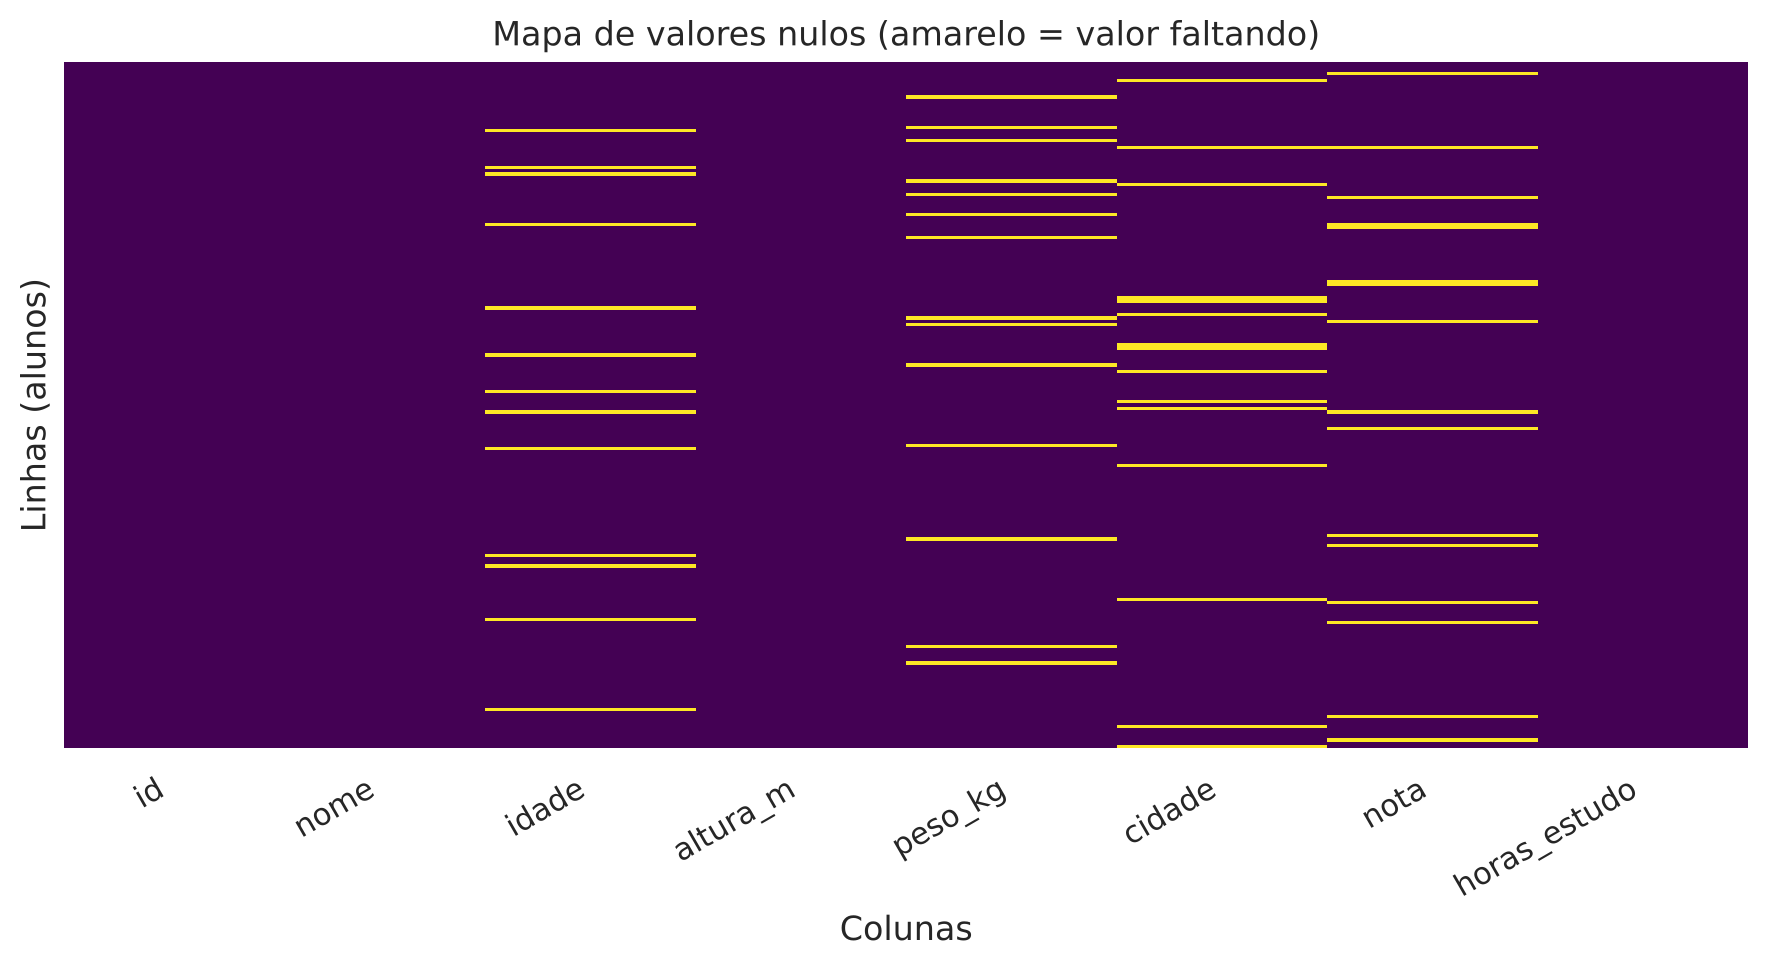

In [10]:
# Visualizando onde estão os nulos (cada faixa clara = um valor faltando)
plt.figure(figsize=(9, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de valores nulos (amarelo = valor faltando)")
plt.xlabel("Colunas")
plt.ylabel("Linhas (alunos)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Como ler o mapa
- Cada **coluna** do gráfico é uma coluna da tabela, e cada **linha horizontal** é um aluno.
- **Roxo** = tem valor; **amarelo** = valor faltando.
- Um traço amarelo **mais grosso** = nulos em alunos **vizinhos** na tabela (linhas seguidas).
- `altura_m` e `horas_estudo` ainda aparecem **sem** nulos: os valores impossíveis delas (altura 0, horas -2) **ainda não** viraram `NaN`. Isso acontece na Parte 4. Ou seja: **não ter nulo não significa que o dado está correto.**

## Parte 4: Valores impossíveis

Um valor pode existir e mesmo assim **não fazer sentido**: idade de -3 anos, altura de 0 m, nota 15 numa escala de 0 a 10.

O `describe()` é o melhor detector: olhe **min** e **max**.

### 📚 Teoria: valor impossível × outlier
São coisas **diferentes**, e confundir as duas é um erro clássico:

| | Valor impossível (erro) | Outlier (valor atípico) |
|---|---|---|
| Definição | viola uma **regra do mundo real** | é **raro**, mas pode existir |
| Exemplo | idade = -3, nota = 15 | um aluno de 1,98 m |
| Dimensão de qualidade | **validade** [6] | não é necessariamente erro |
| O que fazer | corrigir ou virar `NaN` | **investigar**; normalmente se mantém |

As regras de mínimo e máximo se chamam **restrições de domínio** (*domain constraints*). Elas vêm do conhecimento do assunto, não da estatística.

### 🔍 Passo a passo
- `df.describe()` calcula contagem, média, desvio-padrão (`std`), mínimo, quartis (25%, 50%, 75%) e máximo.
- Procure **min** e **max** absurdos: é o jeito mais rápido de achar valores impossíveis.

In [11]:
df.describe().round(2)

,id,idade,altura_m,peso_kg,nota,horas_estudo
count,205.00,192.00,205.00,191.00,189.00,205.00
mean,99.08,17.71,1.74,61.97,6.51,9.56
std,58.36,13.80,1.12,12.01,1.83,5.93
min,1.00,-3.00,0.00,0.00,2.70,-2.00
25%,49.00,16.00,1.61,55.60,5.30,4.00
50%,100.00,16.50,1.67,63.40,6.50,10.00
75%,149.00,18.00,1.72,69.90,7.40,15.00
max,200.00,150.00,17.50,88.00,15.00,19.00


### 4.1 Definir as regras do mundo real

Antes de mexer, escreva **quais valores são possíveis**. Isso depende do assunto, não do Python. Para alunos do ensino médio:

| Coluna | Mínimo | Máximo |
|---|---|---|
| idade | 10 | 25 |
| altura_m | 1.20 | 2.20 |
| peso_kg | 30 | 150 |
| nota | 0 | 10 |
| horas_estudo | 0 | 80 |

### 🔍 Passo a passo do código abaixo
- Criamos um **dicionário** (`{chave: valor}`): a chave é a coluna, o valor é uma tupla `(mínimo, máximo)`.
- Guardar as regras num lugar só permite **reutilizá-las** na detecção, na correção e na validação (Parte 7).

In [12]:
regras = {
    "idade":        (10, 25),
    "altura_m":     (1.20, 2.20),
    "peso_kg":      (30, 150),
    "nota":         (0, 10),
    "horas_estudo": (0, 80),
}

### 4.2 Encontrar os valores impossíveis

`between(min, max)` devolve `True` quando o valor está dentro da faixa. O `~` inverte (vira "fora da faixa"). Também excluímos os nulos para contar só os impossíveis.

### 🔍 Passo a passo
1. `for col, (minimo, maximo) in regras.items()` percorre o dicionário, já separando mínimo e máximo.
2. `df[col].notna()` marca `True` onde **existe** valor.
3. `df[col].between(minimo, maximo)` marca `True` onde o valor está **dentro** da faixa.
4. `~` inverte e `&` significa "E". Juntos: "tem valor **e** está fora da faixa".
5. `fora.sum()` conta os casos, e `df.loc[fora, col]` mostra quais são.

In [13]:
for col, (minimo, maximo) in regras.items():
    fora = df[col].notna() & ~df[col].between(minimo, maximo)
    print(f"{col:13s}: {fora.sum()} impossíveis -> {sorted(df.loc[fora, col].unique().tolist())}")

idade        : 4 impossíveis -> [-3.0, 150.0]
altura_m     : 3 impossíveis -> [0.0, 17.5]
peso_kg      : 2 impossíveis -> [0.0]
nota         : 3 impossíveis -> [15.0]
horas_estudo : 2 impossíveis -> [-2]


### 📚 Teoria extra: a regra de Tukey (1,5 × IQR)
E quando você **não sabe** as regras do mundo real? Tukey [4] propôs uma regra estatística para detectar **outliers**:

- **Q1** = 1º quartil (25% dos dados estão abaixo); **Q3** = 3º quartil (75%).
- **IQR** (*Interquartile Range*, amplitude interquartil) = Q3 − Q1.
- É suspeito o valor **< Q1 − 1,5·IQR** ou **> Q3 + 1,5·IQR**.

Essa é exatamente a regra que o **boxplot** usa para desenhar os pontos soltos (Parte 8). Ela aponta **suspeitos**, mas quem decide se é erro é você.

In [14]:
# Teoria aplicada: regra de Tukey na coluna idade (ainda suja)
q1, q3 = df["idade"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Faixa aceitável pela regra de Tukey: {limite_inf} a {limite_sup}")

suspeitos = df.loc[(df["idade"] < limite_inf) | (df["idade"] > limite_sup), "idade"]
print("Valores suspeitos:", suspeitos.tolist())

Q1 = 16.0, Q3 = 18.0, IQR = 2.0
Faixa aceitável pela regra de Tukey: 13.0 a 21.0
Valores suspeitos: [-3.0, 150.0, -3.0, 150.0]


A regra de Tukey achou os mesmos valores (-3 e 150) **sem** precisarmos dizer quais idades eram possíveis. Na prática, use as duas: **regras do domínio** (para o que é impossível) e **Tukey** (para encontrar o que é estranho).

### 4.3 O que fazer com eles?

Você tem três opções:

1. **Corrigir**, se der para saber o valor certo. Ex.: `17.5` m de altura provavelmente era `1.75`.
2. **Transformar em nulo (`NaN`)**, se não dá para saber. É a opção mais honesta.
3. **Apagar a linha**: só se a linha inteira estiver ruim.

> ⚠️ Nunca troque um valor impossível por um número inventado sem registrar. Transformar em `NaN` e depois tratar os nulos de forma consciente é mais seguro.

### 📚 Teoria
Transformar um erro em `NaN` converte um problema de **validade** em um problema de **completude**, e para completude já temos teoria (Rubin [2]). Atenção: se os erros acontecem mais em certos tipos de valor, os nulos criados podem ser **MNAR**.

### 🔍 Passo a passo
1. `df["altura_m"].between(10, 25)` encontra alturas que parecem ter sido digitadas sem a vírgula.
2. `df.loc[filtro, "altura_m"] = df["altura_m"] / 10` corrige **só** essas linhas (o pandas alinha pelo índice).
3. O `for` reaplica as regras e troca por `np.nan` tudo que ainda estiver fora da faixa.
4. O `describe()` final serve para **conferir** o resultado.

In [15]:
# 1) Corrigir o que dá para deduzir: altura digitada sem a vírgula (17.5 -> 1.75)
df.loc[df["altura_m"].between(10, 25), "altura_m"] = df["altura_m"] / 10

# 2) Todo o resto que estiver fora da faixa vira NaN
for col, (minimo, maximo) in regras.items():
    fora = df[col].notna() & ~df[col].between(minimo, maximo)
    df.loc[fora, col] = np.nan

df.describe().round(2)

,id,idade,altura_m,peso_kg,nota,horas_estudo
count,205.00,188.00,203.00,189.00,186.00,203.00
mean,99.08,16.53,1.68,62.63,6.37,9.67
std,58.36,1.12,0.09,10.23,1.48,5.84
min,1.00,15.00,1.45,38.70,2.70,0.00
25%,49.00,16.00,1.62,56.10,5.30,5.00
50%,100.00,16.50,1.67,63.60,6.40,10.00
75%,149.00,18.00,1.72,70.00,7.40,15.00
max,200.00,18.00,1.94,88.00,10.00,19.00


Agora min e max fazem sentido. ✅

## Parte 5: Texto bagunçado e duplicados

### 📚 Teoria: consistência e unicidade
- **Consistência** [6]: o mesmo valor do mundo real deve ter **uma única representação**. Padronizar categorias é um caso simples de **resolução de entidades** (*entity resolution*): descobrir quando registros diferentes falam da mesma coisa.
- **Unicidade** [6]: cada entidade (aluno) aparece **uma vez**. Duplicados dão mais peso a alguns alunos e **enviesam** médias e contagens.

### 5.1 Padronizar texto

Para o computador, `"São Paulo"`, `"  São Paulo "`, `"sao paulo"` e `"SP"` são **quatro cidades diferentes**.

### 🔍 Passo a passo
- `.str` dá acesso aos métodos de texto do pandas para a coluna inteira de uma vez (**operação vetorizada**).
- `.str.strip()` remove espaços no começo e no fim.
- `.str.lower()` deixa tudo minúsculo, para que "SÃO PAULO" e "são paulo" fiquem iguais.
- `.replace(dicionário)` troca cada variação pelo nome oficial.
- **Ordem importa:** primeiro normalizamos (strip + lower) para o dicionário ficar pequeno.

In [16]:
df["cidade"].value_counts()

cidade
Curitiba          53
Belo Horizonte    50
Rio de Janeiro    41
São Paulo         35
sao paulo          4
  São Paulo        2
SP                 2
RIO DE JANEIRO     2
Rio de janeiro     1
Name: count, dtype: int64

In [17]:
# Passo 1: tirar espaços nas pontas e colocar tudo em minúsculas
df["cidade"] = df["cidade"].str.strip().str.lower()

# Passo 2: mapear cada variação para o nome oficial
padrao = {
    "são paulo": "São Paulo",
    "sao paulo": "São Paulo",
    "sp": "São Paulo",
    "rio de janeiro": "Rio de Janeiro",
    "belo horizonte": "Belo Horizonte",
    "curitiba": "Curitiba",
}
df["cidade"] = df["cidade"].replace(padrao)

df["cidade"].value_counts(dropna=False)

cidade
Curitiba          53
Belo Horizonte    50
Rio de Janeiro    44
São Paulo         43
NaN               15
Name: count, dtype: int64

### 5.2 Remover duplicados

Linhas repetidas fazem um aluno "contar duas vezes" nas médias.

### 🔍 Passo a passo
- `df.duplicated()` marca `True` nas linhas idênticas a uma anterior.
- `df["id"].duplicated()` verifica só a **chave** (o identificador do aluno). É mais rigoroso: pega duplicados mesmo quando outra coluna mudou um pouco.
- `drop_duplicates(subset="id", keep="first")` mantém a primeira ocorrência de cada id.

In [18]:
print("Linhas duplicadas:", df.duplicated().sum())
print("IDs repetidos:   ", df["id"].duplicated().sum())

df = df.drop_duplicates(subset="id", keep="first")
print("Linhas agora:", len(df))

Linhas duplicadas: 5
IDs repetidos:    5
Linhas agora: 200


## Parte 6: Tratar os nulos: apagar ou preencher?

Não existe resposta única. Um guia prático:

| Situação | O que fazer |
|---|---|
| Poucos nulos (< 5%) e muitos dados | Pode **apagar** as linhas (`dropna`) |
| Coluna numérica com nulos | **Preencher** com a **mediana** (resiste a valores extremos) |
| Coluna de texto/categoria | Preencher com `"Desconhecido"` ou com a **moda** (valor mais comum) |
| Coluna com > 50% de nulos | Pensar em **remover a coluna** |
| O nulo é a variável que você quer estudar | **Não preencha**, analise só as linhas com valor |

> 💡 Por que **mediana** e não **média**? Se um valor for muito alto, a média "puxa" para cima; a mediana quase não muda.

### 📚 Teoria 1: apagar (*listwise deletion*)
Apagar linhas com nulos é chamado de **análise de casos completos**. Segundo Little & Rubin [3], ela só dá resultados **sem viés** quando os dados são **MCAR**. Se forem MAR ou MNAR, as linhas que sobram não representam bem o todo. Além disso, você **perde dados**.

### 📚 Teoria 2: preencher (*imputação simples*)
Preencher é chamado de **imputação**. O efeito colateral mais importante [3][13]: **imputar com um valor fixo reduz a variabilidade** (desvio-padrão) dos dados, porque muitos valores iguais são colocados no centro. Os dados parecem "mais certos" do que realmente são. Técnicas avançadas, como a **imputação múltipla** de van Buuren [13], resolvem isso, mas estão além deste tutorial.

### 📚 Teoria 3: por que a mediana é *robusta*
Na estatística robusta [5], o **ponto de ruptura** (*breakdown point*) é a fração de dados errados que um estimador aguenta antes de dar um resultado absurdo:
- **Média**: ponto de ruptura de **0%**. **Um único** valor absurdo já estraga o resultado.
- **Mediana**: ponto de ruptura de **50%**. Ela aguenta até metade dos dados errados.

A célula logo depois da próxima mostra isso na prática.

Primeiro, guardamos uma cópia **antes** de preencher para comparar depois:

In [19]:
df_antes = df.copy()
df.isna().sum()

id               0
nome             0
idade           17
altura_m         2
peso_kg         16
cidade          14
nota            18
horas_estudo     2
dtype: int64

In [20]:
# Teoria aplicada: média x mediana quando há UM valor absurdo
pesos = pd.Series([60, 62, 61, 63, 64])
pesos_com_erro = pd.Series([60, 62, 61, 63, 6400])   # alguém digitou 6400 em vez de 64

print("Sem erro -> média:", pesos.mean(), "| mediana:", pesos.median())
print("Com erro -> média:", pesos_com_erro.mean(), "| mediana:", pesos_com_erro.median())

Sem erro -> média: 62.0 | mediana: 62.0
Com erro -> média: 1329.2 | mediana: 62.0


A média saltou de 62 para **1329,2**, enquanto a mediana ficou em **62**. É por isso que preferimos a mediana para preencher nulos.

### 6.1 Apagar: quando a informação é essencial

A `nota` é o centro da nossa análise. Inventar notas distorceria tudo, então apagamos as linhas sem nota.

### 🔍 Passo a passo
- `dropna(subset=["nota"])` apaga **apenas** as linhas em que a `nota` é nula. As outras colunas não são consideradas.
- Por que aqui apagar é aceitável? A nota é a **variável de interesse**, e imputá-la criaria notas falsas que afetariam diretamente as conclusões.

In [21]:
df = df.dropna(subset=["nota"])
print("Linhas restantes:", len(df))

Linhas restantes: 182


### 6.2 Preencher números com a mediana

Para `idade` uma mediana geral serve. Para `altura` e `peso` usamos a **mediana do grupo** (ex.: por cidade). É mais realista que uma mediana única para todo mundo.

### 📚 Teoria: imputação condicional (por grupo)
Preencher com a mediana **do grupo** assume que o dado é **MAR** [2]: a falta (e o valor provável) depende de algo que conhecemos, como a cidade. É uma estimativa melhor do que uma mediana única para todos.

### 🔍 Passo a passo
1. `fillna(valor)` troca os `NaN` pelo valor informado.
2. `df.groupby("cidade")["peso_kg"]` separa os pesos por cidade.
3. `.transform("median")` calcula a mediana de cada cidade e **devolve uma coluna do mesmo tamanho do `df`**, com a mediana do grupo de cada linha. É isso que permite usar o resultado direto no `fillna`. (Já o `.agg("median")` devolveria uma linha por cidade.)
4. O segundo `fillna` com a mediana geral cobre alunos **sem cidade**, que não têm grupo.

In [22]:
df["idade"] = df["idade"].fillna(df["idade"].median())
df["horas_estudo"] = df["horas_estudo"].fillna(df["horas_estudo"].median())

# mediana por grupo com groupby + transform (mantém o tamanho da tabela)
df["peso_kg"] = df["peso_kg"].fillna(df.groupby("cidade")["peso_kg"].transform("median"))
df["altura_m"] = df["altura_m"].fillna(df.groupby("cidade")["altura_m"].transform("median"))

# se a cidade também era nula, o grupo não existe; usamos a mediana geral
df["peso_kg"] = df["peso_kg"].fillna(df["peso_kg"].median())
df["altura_m"] = df["altura_m"].fillna(df["altura_m"].median())

In [23]:
# Teoria aplicada: a imputação reduz o desvio-padrão (variabilidade)
comparacao = pd.DataFrame({
    # mesmas linhas nos dois lados (df_antes.loc[df.index]) para a comparação ser justa
    "antes (só valores reais)": df_antes.loc[df.index, "peso_kg"].describe(),
    "depois (com imputação)":   df["peso_kg"].describe(),
}).round(2)
comparacao

,antes (só valores reais),depois (com imputação)
count,167.00,182.00
mean,62.42,62.50
std,10.33,9.92
min,38.70,38.70
25%,55.60,56.72
50%,62.90,63.18
75%,70.05,69.45
max,88.00,88.00


Compare a linha **std** (desvio-padrão): depois da imputação ela fica **menor**. É o efeito previsto por Little & Rubin [3]. Com poucos nulos o efeito é pequeno; com muitos nulos ele pode enganar a análise. Por isso **sempre documente** o que foi imputado.

### 6.3 Preencher texto com uma categoria

### 📚 Teoria
Para variáveis **categóricas** não existe média nem mediana. As opções são a **moda** (o valor mais frequente) ou uma categoria explícita como `"Desconhecida"`. A categoria explícita é mais **honesta**, porque mantém visível que o dado faltava (isso pode até ser informação útil).

### 🔍 Passo a passo
- `fillna("Desconhecida")` troca os nulos de texto.
- `astype(int)` converte a idade para inteiro. Isso só é possível **depois** de remover todos os `NaN`, porque `NaN` é um número decimal (*float*) [19].

In [24]:
df["cidade"] = df["cidade"].fillna("Desconhecida")
df["idade"] = df["idade"].astype(int)     # idade sem casas decimais

df.isna().sum()

id              0
nome            0
idade           0
altura_m        0
peso_kg         0
cidade          0
nota            0
horas_estudo    0
dtype: int64

Zero nulos! 🎉

## Parte 7: Validar a limpeza

Profissionais **testam** se a limpeza funcionou. O `assert` gera um erro se a condição for falsa. Se a célula rodar sem erro, está tudo certo.

### 📚 Teoria: validação de dados
Validar é verificar se os dados respeitam **contratos** (regras que devem ser sempre verdadeiras). É a mesma ideia dos **testes automatizados** em programação: se alguém mudar o arquivo de origem e aparecer um dado novo e ruim, o `assert` avisa na hora. Repare que reutilizamos o dicionário `regras` da Parte 4: **uma única fonte de verdade**.

### 🔍 Passo a passo
- `assert condição, "mensagem"` não faz nada se a condição for verdadeira e **para o programa** com a mensagem se for falsa.
- `df.isna().sum().sum()` soma os nulos de todas as colunas (duas somas: por coluna e depois o total).
- `.is_unique` é `True` se não houver valores repetidos.
- `.all()` é `True` se **todos** os valores forem `True`.
- `to_csv("alunos_limpo.csv")` salva o resultado limpo. **Nunca sobrescreva o arquivo original**, para poder refazer tudo do zero.

In [25]:
assert df.isna().sum().sum() == 0, "Ainda existem nulos!"
assert df["id"].is_unique, "Existem IDs repetidos!"
for col, (minimo, maximo) in regras.items():
    assert df[col].between(minimo, maximo).all(), f"{col} tem valor impossível!"

print("✅ Todos os testes passaram!")
df.to_csv("alunos_limpo.csv", index=False)
df.describe().round(2)

✅ Todos os testes passaram!


,id,idade,altura_m,peso_kg,nota,horas_estudo
count,182.00,182.00,182.00,182.00,182.00,182.00
mean,101.01,16.48,1.68,62.50,6.39,9.63
std,58.16,1.06,0.09,9.92,1.50,5.77
min,1.00,15.00,1.49,38.70,2.70,0.00
25%,52.25,16.00,1.62,56.72,5.30,5.00
50%,101.50,16.00,1.67,63.18,6.50,9.50
75%,150.75,17.00,1.72,69.45,7.40,14.75
max,200.00,18.00,1.94,88.00,10.00,19.00


## Parte 8: Visualização de dados

Com os dados limpos, os gráficos finalmente contam a verdade.

### 📚 Teoria 1: por que visualizar? (o Quarteto de Anscombe)
Anscombe [11] criou quatro conjuntos de dados com **a mesma média, variância e correlação**, mas com formas completamente diferentes quando desenhados. Lição: **estatísticas resumidas não bastam; sempre faça o gráfico.**

### 📚 Teoria 2: a percepção visual (Cleveland & McGill)
Cleveland & McGill [8] mediram com que precisão as pessoas leem cada tipo de codificação visual. Do **mais preciso** para o **menos preciso**:
1. **Posição em uma escala comum** (pontos, barras alinhadas)
2. Comprimento
3. Ângulo e inclinação
4. Área
5. Cor e saturação

Por isso gráficos de **barras** e de **pontos** costumam ser melhores que gráficos de **pizza** (ângulo/área), e a **cor** deve ser usada para separar grupos, não para comparar valores exatos.

### 📚 Teoria 3: menos é mais (Tufte)
Tufte [9] definiu a razão **dados-tinta** (*data-ink ratio*): a maior parte da "tinta" de um gráfico deve mostrar **dados**. Tire enfeites, sombras e 3D. Título e eixos claros são obrigatórios.

### 📚 Teoria 4: a gramática dos gráficos
Wilkinson [10] mostrou que todo gráfico é composto por **dados + mapeamento estético (x, y, cor) + forma geométrica**. O seaborn segue essa ideia: `sns.scatterplot(data=df, x=..., y=..., hue=...)` é literalmente "use estes **dados**, mapeie estas colunas para **x, y e cor** e desenhe **pontos**".

### Qual gráfico usar?

| Pergunta | Gráfico | Comando |
|---|---|---|
| Como os valores se distribuem? | Histograma | `sns.histplot` |
| Tem valor estranho? Como os grupos se comparam? | Boxplot | `sns.boxplot` |
| Quantos de cada categoria? | Barras de contagem | `sns.countplot` |
| Qual a média por grupo? | Barras | `sns.barplot` |
| Duas variáveis numéricas se relacionam? | Dispersão | `sns.scatterplot` / `sns.regplot` |
| Quais variáveis andam juntas? | Mapa de calor | `sns.heatmap` |

Todo gráfico deve ter **título** e **nomes nos eixos**.

### 8.1 Por que limpar? Antes vs depois

### 🔍 Passo a passo
- `plt.subplots(1, 2)` cria uma figura com 1 linha e 2 gráficos lado a lado; `axes[0]` e `axes[1]` são cada um deles.
- `ax=axes[0]` diz ao seaborn em qual espaço desenhar.
- `plt.tight_layout()` ajusta os espaçamentos para nada ficar sobreposto.

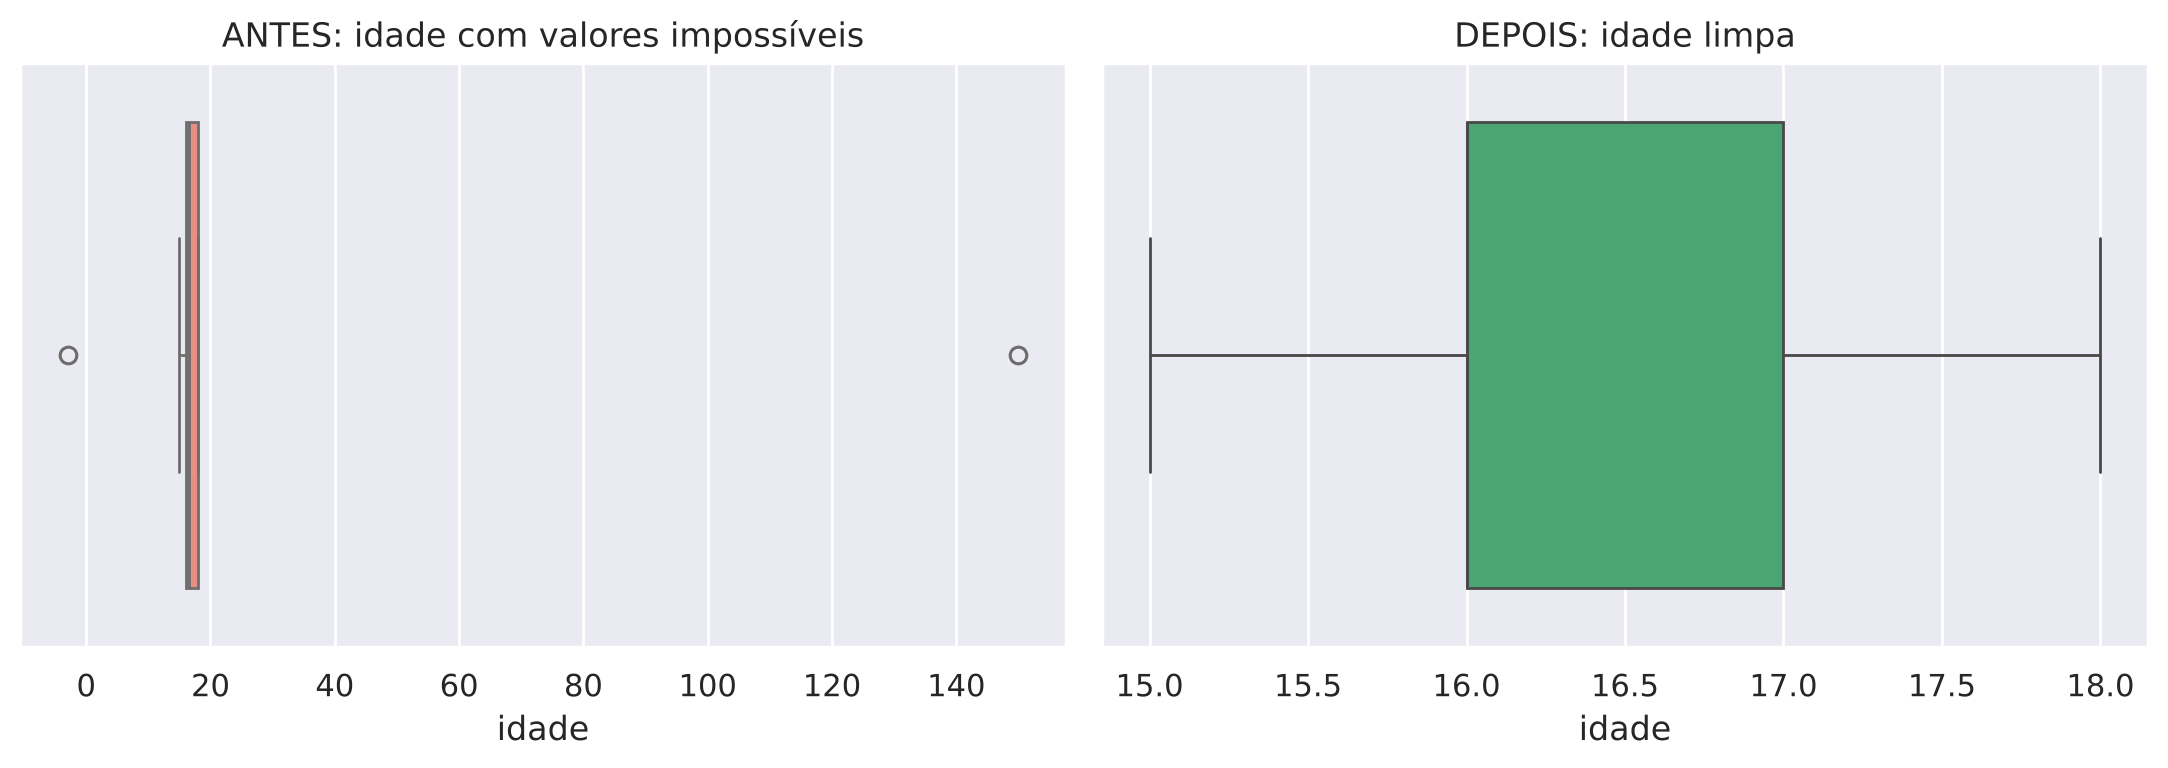

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(x=pd.read_csv("alunos_sujo.csv", na_values=disfarces)["idade"].astype(float), ax=axes[0], color="salmon")
axes[0].set_title("ANTES: idade com valores impossíveis")

sns.boxplot(x=df["idade"], ax=axes[1], color="mediumseagreen")
axes[1].set_title("DEPOIS: idade limpa")

plt.tight_layout()
plt.show()

Os pontos lá longe no gráfico da esquerda (-3 e 150 anos) achatam todo o resto. O boxplot é ótimo para **encontrar** valores impossíveis.

### 📚 Teoria
O boxplot de Tukey [4] desenha como pontos soltos os valores fora de **Q1 − 1,5·IQR** e **Q3 + 1,5·IQR**, a mesma regra que você aplicou na Parte 4. Além disso, os valores extremos **esticam a escala** do eixo e "espremem" os dados reais. Os erros não só atrapalham as contas, mas **escondem** o padrão verdadeiro.

### 8.2 Histograma: distribuição das notas

### 📚 Teoria
- O **histograma** divide os valores em intervalos (*bins*) e conta quantos caem em cada um. Ele mostra a **forma** da distribuição: simétrica, assimétrica, com um ou dois picos.
- A escolha dos *bins* muda a aparência. Uma regra clássica é a de **Freedman–Diaconis** [15], que usa o IQR para calcular a largura ideal.
- `kde=True` desenha uma **estimativa de densidade por kernel** [16]: uma curva suave que estima a distribuição "por trás" dos dados.

### 🔍 Passo a passo
- `bins=15` define 15 intervalos.
- `plt.axvline(...)` desenha uma linha vertical na média; `label=` é o texto da legenda.
- `f"{valor:.1f}"` formata o número com 1 casa decimal.

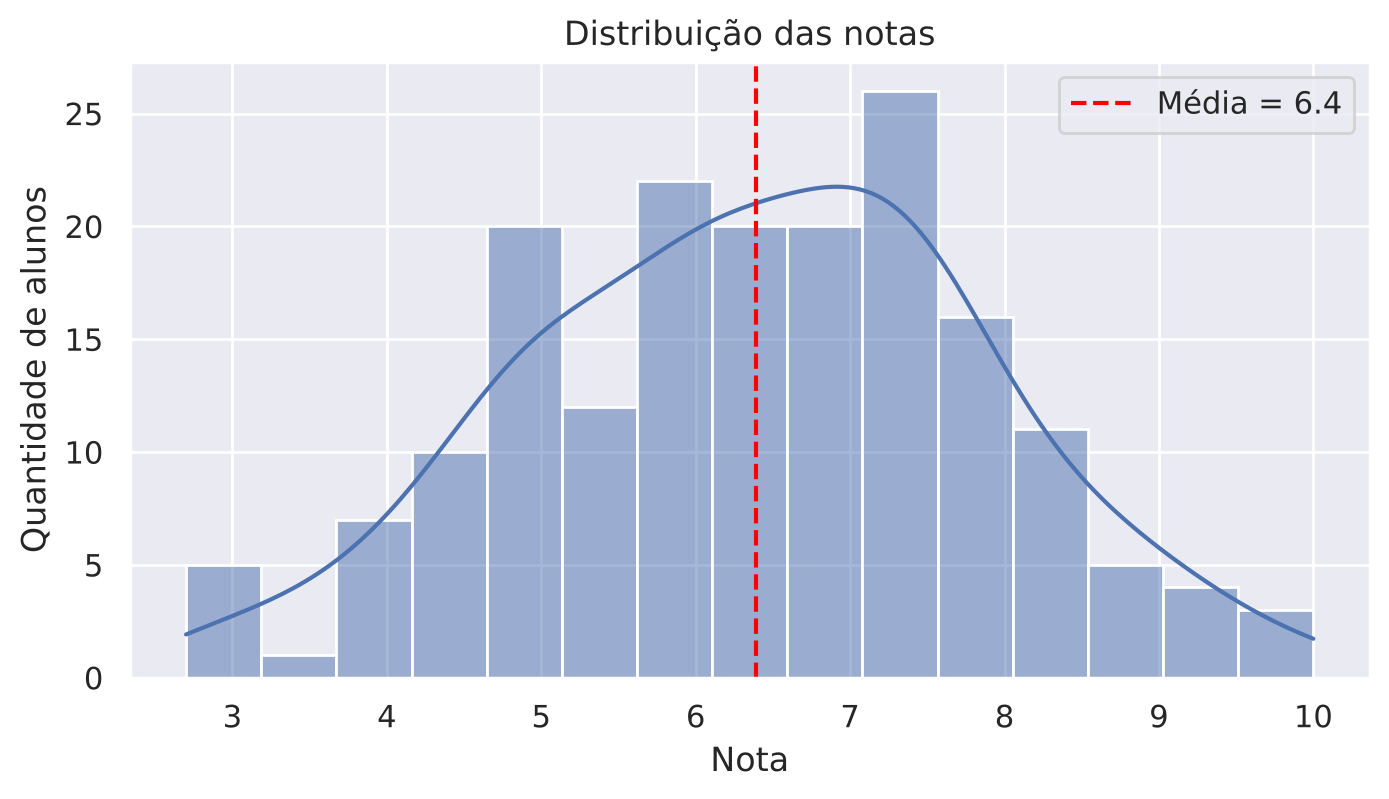

In [27]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="nota", bins=15, kde=True)
plt.axvline(df["nota"].mean(), color="red", linestyle="--", label=f"Média = {df['nota'].mean():.1f}")
plt.title("Distribuição das notas")
plt.xlabel("Nota")
plt.ylabel("Quantidade de alunos")
plt.legend()
plt.show()

### 8.3 Barras de contagem: alunos por cidade

### 📚 Teoria
- Barras usam **comprimento a partir de uma base comum**, a codificação mais precisa depois da posição [8]. Por isso **o eixo precisa começar em zero**; cortar a base exagera as diferenças.
- **Ordenar** as barras (da maior para a menor) facilita a comparação.
- Barras **horizontais** (`y=`) deixam os nomes longos legíveis.

### 🔍 Passo a passo
- `value_counts().index` devolve as cidades já ordenadas da mais frequente para a menos frequente.
- `order=ordem` aplica essa ordem ao gráfico.

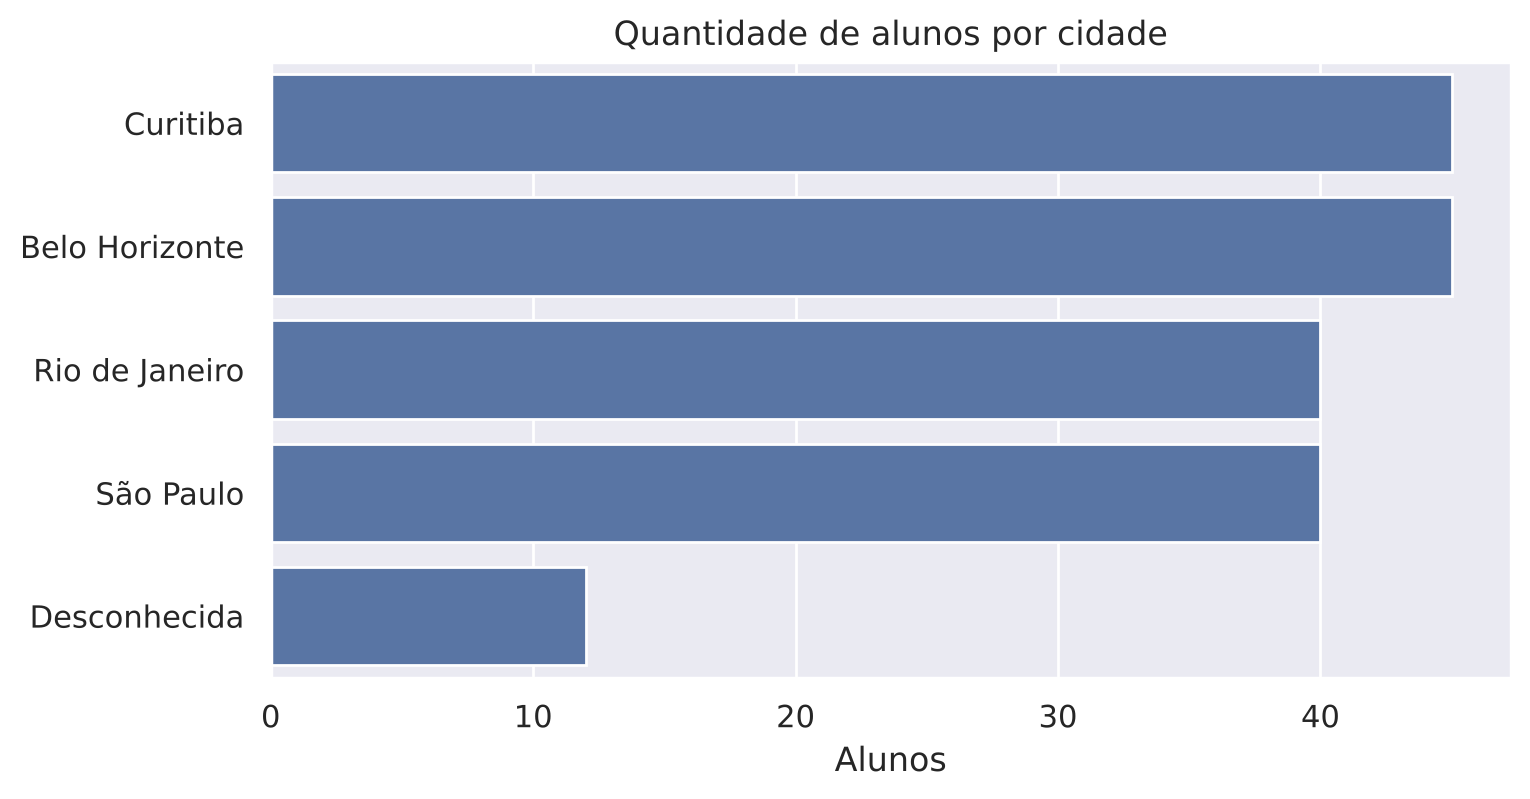

In [28]:
plt.figure(figsize=(8, 4))
ordem = df["cidade"].value_counts().index
sns.countplot(data=df, y="cidade", order=ordem)
plt.title("Quantidade de alunos por cidade")
plt.xlabel("Alunos")
plt.ylabel("")
plt.show()

### 8.4 Boxplot por grupo: notas por cidade

### 📚 Teoria
O boxplot é um resumo visual dos **cinco números** de Tukey [4]: mínimo, Q1, mediana, Q3 e máximo (dentro das hastes). Colocar vários boxplots **lado a lado** permite comparar a mediana e a dispersão de grupos de uma vez.

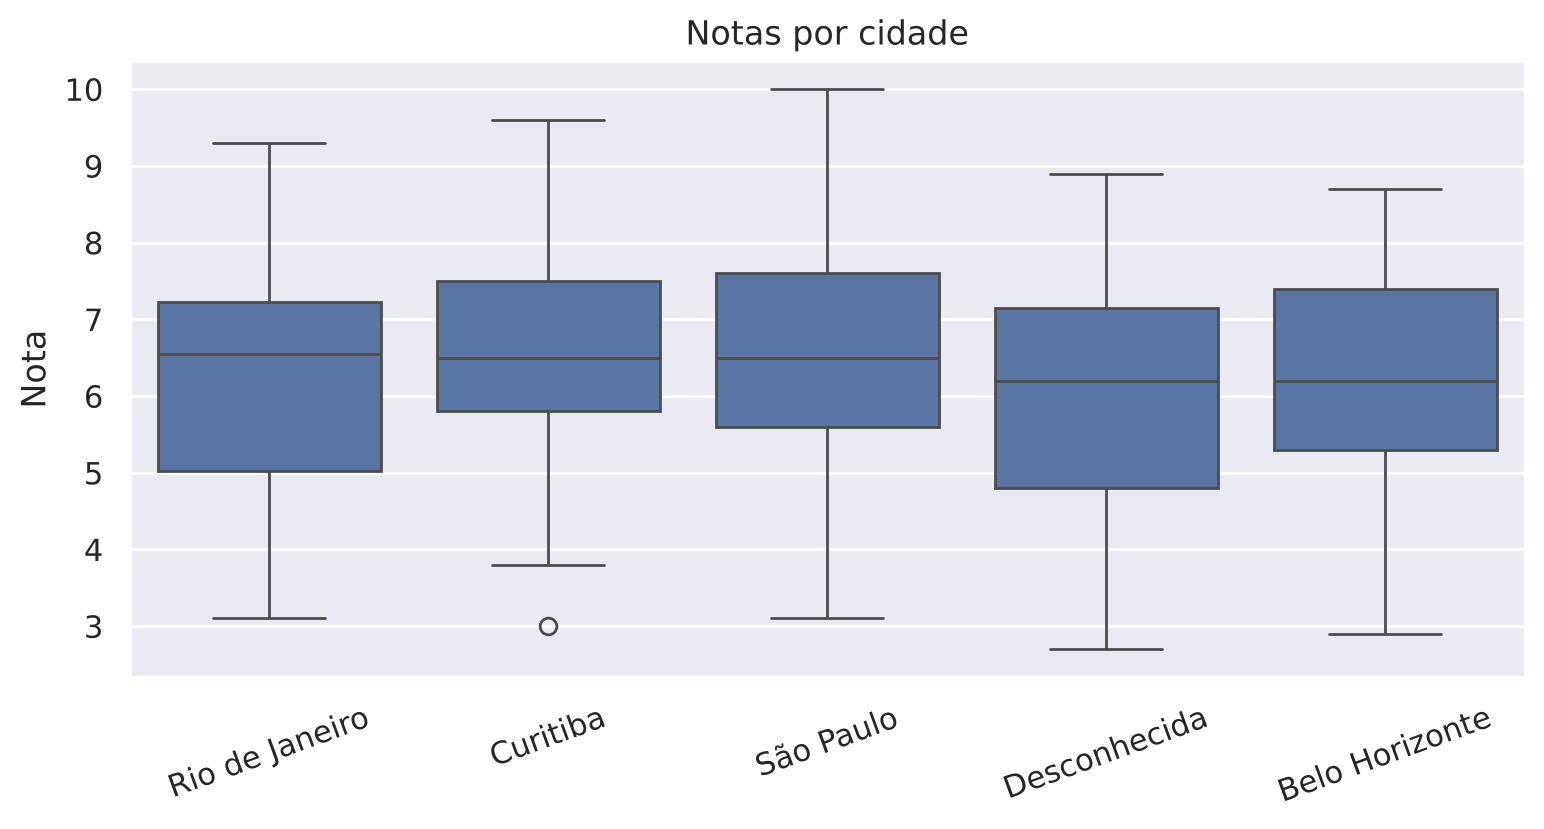

In [29]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="cidade", y="nota")
plt.title("Notas por cidade")
plt.xlabel("")
plt.ylabel("Nota")
plt.xticks(rotation=20)
plt.show()

**Como ler um boxplot:** a linha do meio é a **mediana**; a caixa contém os 50% do meio; as "hastes" mostram o resto; pontos soltos são possíveis **outliers**.

### 8.5 Dispersão: horas de estudo × nota

### 📚 Teoria
- O gráfico de **dispersão** usa **posição em x e y**, a codificação mais precisa de todas [8]. É ideal para ver a relação entre **duas variáveis numéricas**.
- `regplot` adiciona a reta de **regressão linear** por **mínimos quadrados**: a reta que minimiza a soma dos quadrados das distâncias verticais até os pontos.
- A faixa sombreada é o **intervalo de confiança** de 95% da reta.

### 🔍 Passo a passo
- `scatter_kws={"alpha": 0.5}` deixa os pontos semitransparentes, o que mostra onde há sobreposição.
- `df["a"].corr(df["b"])` calcula a **correlação de Pearson** [14].

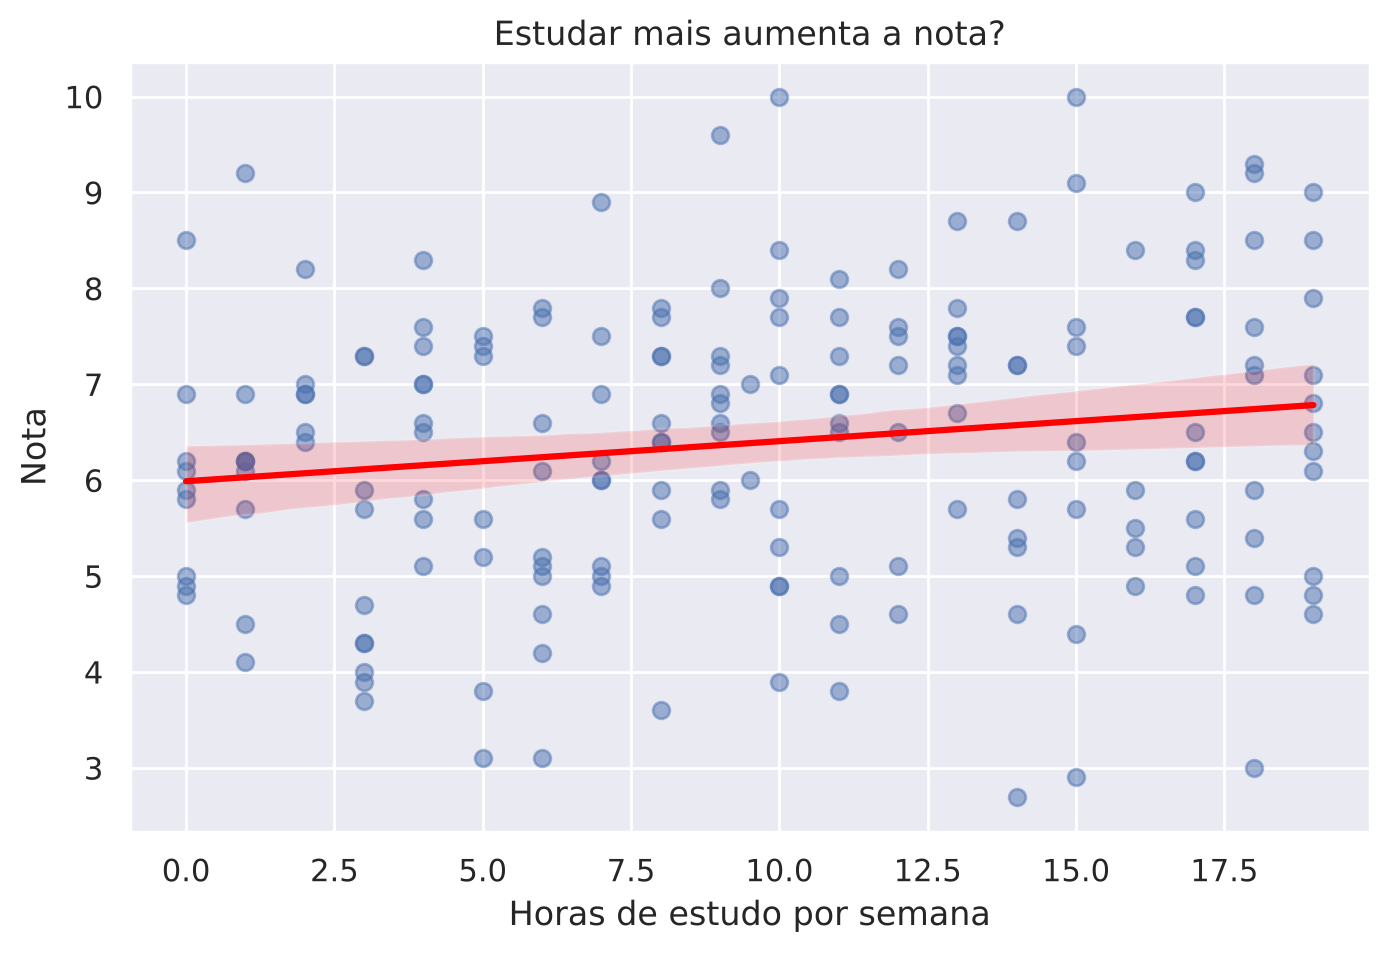

Correlação: 0.16


In [30]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="horas_estudo", y="nota",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Estudar mais aumenta a nota?")
plt.xlabel("Horas de estudo por semana")
plt.ylabel("Nota")
plt.show()

print("Correlação:", round(df["horas_estudo"].corr(df["nota"]), 2))

A **correlação** vai de -1 a 1. Perto de 0 = sem relação; perto de 1 = sobem juntas; perto de -1 = uma sobe e a outra desce.
(Como os dados são aleatórios, aqui deve dar perto de 0.)

### 📚 Teoria: correlação de Pearson
- O **r** de Pearson [14] mede a força da relação **linear** entre duas variáveis.
- **r²** é a fração da variação de uma variável "explicada" pela outra. Ex.: r = 0,16 → r² ≈ 0,03, ou seja, só ~3%.
- ⚠️ **Correlação não é causalidade.** Mesmo uma correlação alta não prova que uma coisa causa a outra.
- ⚠️ Pearson só enxerga relações **lineares**; uma relação em curva pode dar r ≈ 0. Por isso, olhe o gráfico (lembre-se de Anscombe [11]).

### 8.6 Mapa de calor das correlações

### 📚 Teoria
- O mapa de calor usa **cor** (a codificação menos precisa [8]). Por isso colocamos `annot=True` para escrever os números em cima.
- Usamos uma escala de cores **divergente** (`coolwarm`) centrada no zero, com `vmin=-1, vmax=1`: azul para negativo, vermelho para positivo e cinza claro perto de zero. Escalas divergentes servem para dados que têm um **ponto central com significado** [10].
- A diagonal é sempre 1, porque cada variável tem correlação perfeita consigo mesma.

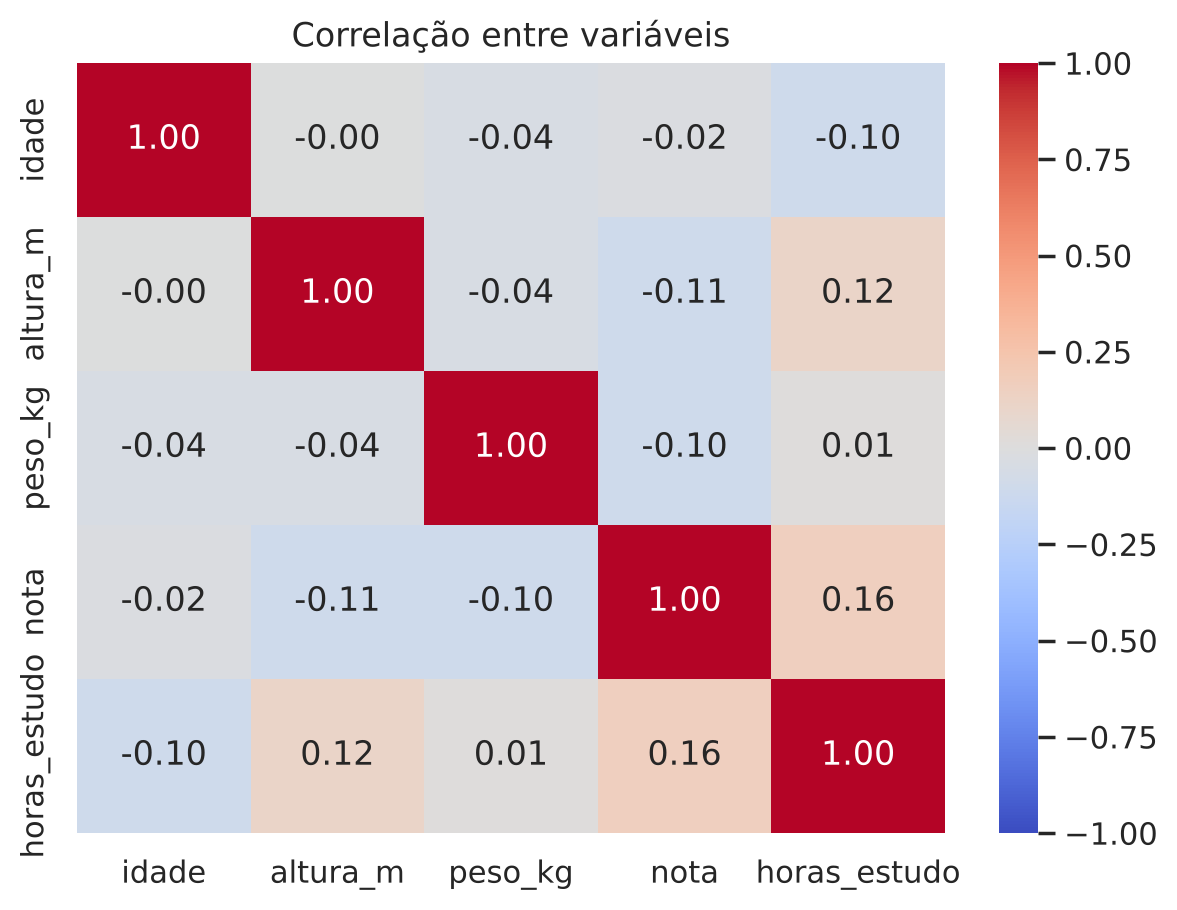

In [31]:
plt.figure(figsize=(7, 5))
corr = df[["idade", "altura_m", "peso_kg", "nota", "horas_estudo"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis")
plt.show()

### 8.7 Vários gráficos em uma figura (painel)

### 📚 Teoria: *small multiples*
Tufte [9] chamou de **small multiples** a ideia de mostrar vários gráficos pequenos, com o mesmo estilo, lado a lado. O olho compara tudo de uma vez. É a base de qualquer **painel** (*dashboard*).

### 🔍 Passo a passo
- `plt.subplots(2, 2)` cria uma grade 2×2; `axes[linha, coluna]` acessa cada gráfico.
- `errorbar=None` remove as barras de erro do `barplot`.
- `plt.suptitle` é o título geral da figura.
- `plt.savefig("arquivo.png", dpi=150)` salva a imagem. Chame **antes** do `plt.show()`, senão a imagem sai em branco.

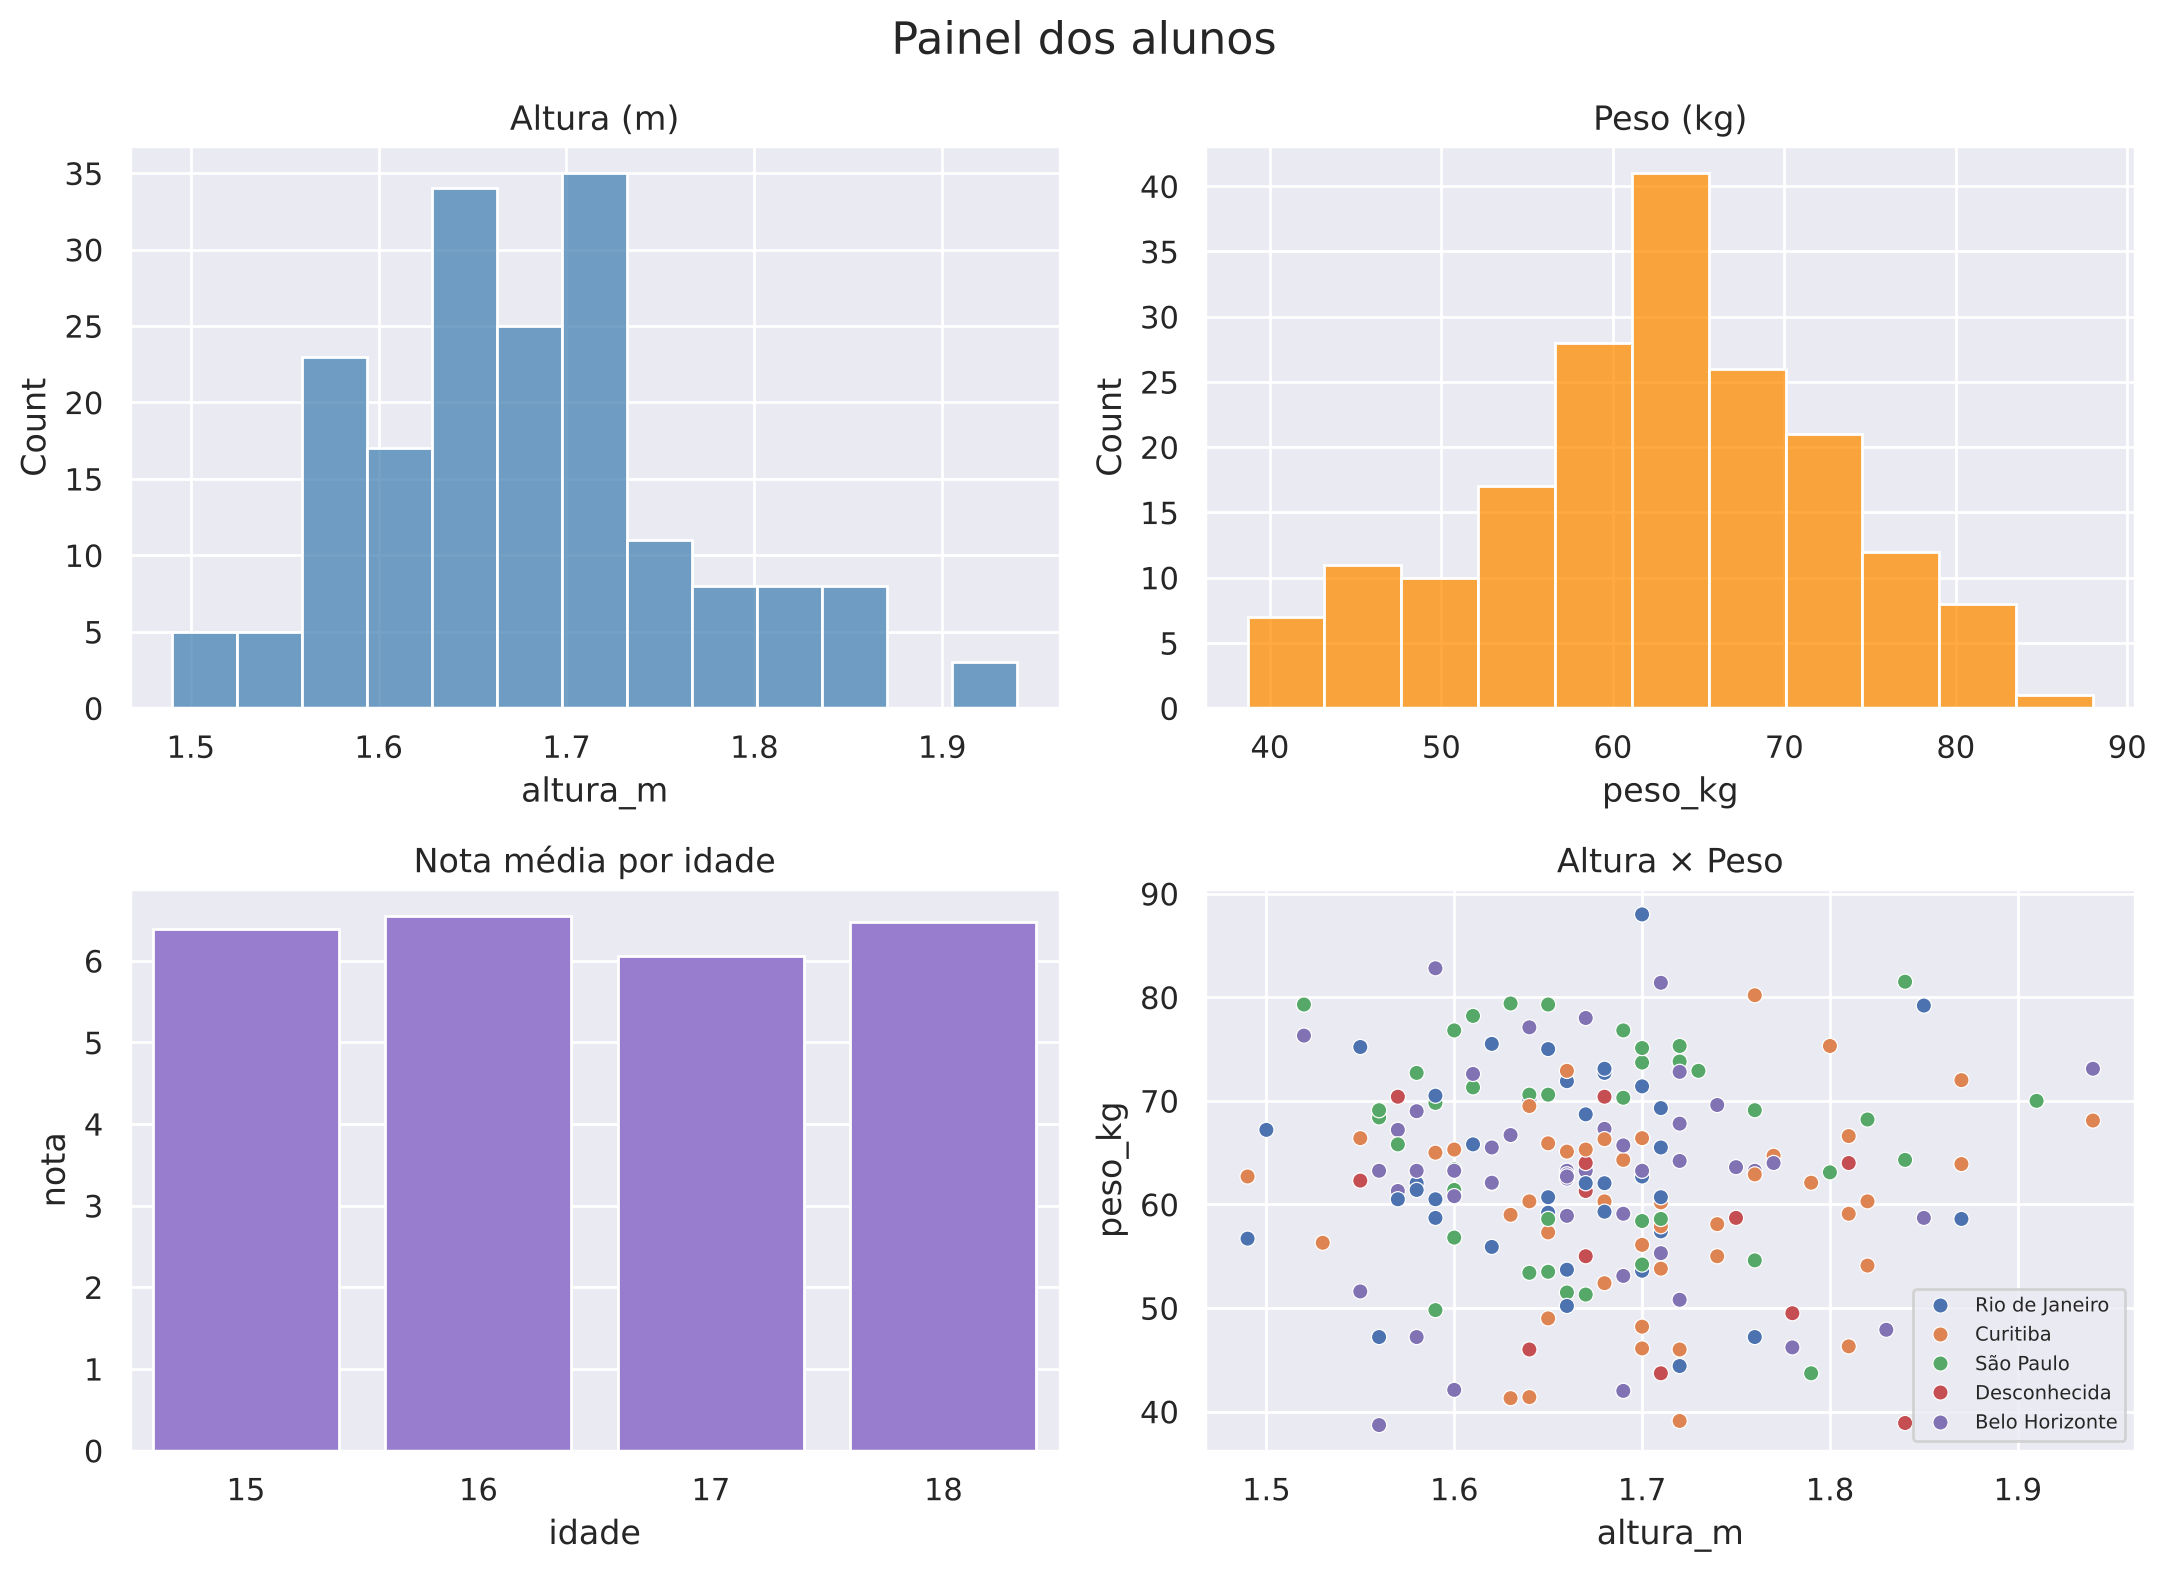

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

sns.histplot(df["altura_m"], ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Altura (m)")

sns.histplot(df["peso_kg"], ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Peso (kg)")

sns.barplot(data=df, x="idade", y="nota", ax=axes[1, 0], errorbar=None, color="mediumpurple")
axes[1, 0].set_title("Nota média por idade")

sns.scatterplot(data=df, x="altura_m", y="peso_kg", hue="cidade", ax=axes[1, 1], s=30)
axes[1, 1].set_title("Altura × Peso")
axes[1, 1].legend(fontsize=7)

plt.suptitle("Painel dos alunos", fontsize=16)
plt.tight_layout()
plt.savefig("painel_alunos.png", dpi=150)   # salva a imagem
plt.show()

## Parte 9: Exercícios

Tente fazer sozinho antes de olhar as dicas. Use `df` (limpo) ou recarregue `alunos_sujo.csv` para treinar a limpeza.

1. **Nulos:** recarregue `alunos_sujo.csv` **sem** `na_values`. Quantos nulos aparecem na coluna `nota`? E com `na_values`? Explique a diferença.
2. **Impossíveis:** quantos alunos tinham `peso_kg` igual a 0 no arquivo sujo? *(Dica: `df_sujo = pd.read_csv("alunos_sujo.csv")` e depois `(df_sujo["peso_kg"] == 0).sum()`)*
3. **Nova coluna:** crie a coluna `imc = peso_kg / altura_m ** 2`. Há algum IMC impossível (menor que 12 ou maior que 50)?
4. **Categorias:** crie a coluna `situacao` com `"Aprovado"` se nota ≥ 6, senão `"Reprovado"`. *(Dica: `np.where`)*
5. **Agrupar:** qual cidade tem a maior nota média? *(Dica: `df.groupby("cidade")["nota"].mean()`)*
6. **Gráfico:** faça um `countplot` de `situacao` separado por cidade (`hue="cidade"`), com título e eixos.
7. **Desafio:** em vez de apagar as linhas sem `nota` (Parte 6.1), preencha com a mediana. Compare os histogramas de antes e depois. O que aparece de estranho? *(Dica: um "pico" artificial na mediana.)*

---

### Resumo do fluxo (cole na parede! 📌)

1. **Olhar**: `head`, `info`, `describe`, `value_counts`
2. **Revelar nulos disfarçados**: `na_values`, `pd.to_numeric(errors="coerce")`
3. **Achar impossíveis**: regras de mín/máx + `between`
4. **Corrigir ou transformar em `NaN`**
5. **Padronizar texto**: `str.strip().str.lower()` + `replace`
6. **Remover duplicados**: `drop_duplicates`
7. **Tratar nulos**: `dropna` ou `fillna` (mediana / moda / categoria)
8. **Validar**: `assert`
9. **Visualizar**: escolher o gráfico pela pergunta

---

## Referências

**Data wrangling e qualidade de dados**
- [1] Wickham, H. (2014). Tidy Data. *Journal of Statistical Software*, 59(10), 1–23. https://doi.org/10.18637/jss.v059.i10
- [6] Wang, R. Y., & Strong, D. M. (1996). Beyond Accuracy: What Data Quality Means to Data Consumers. *Journal of Management Information Systems*, 12(4), 5–33.
- [7] Kandel, S., Heer, J., Plaisant, C., et al. (2011). Research directions in data wrangling: Visualizations and transformations for usable and credible data. *Information Visualization*, 10(4), 271–288.
- [18] Chapman, P., Clinton, J., Kerber, R., et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc.

**Dados faltantes**
- [2] Rubin, D. B. (1976). Inference and Missing Data. *Biometrika*, 63(3), 581–592.
- [3] Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3ª ed.). Wiley.
- [13] van Buuren, S. (2018). *Flexible Imputation of Missing Data* (2ª ed.). CRC Press. Gratuito em https://stefvanbuuren.name/fimd/

**Estatística exploratória e robusta**
- [4] Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- [5] Huber, P. J., & Ronchetti, E. M. (2009). *Robust Statistics* (2ª ed.). Wiley.
- [14] Pearson, K. (1895). Notes on Regression and Inheritance in the Case of Two Parents. *Proceedings of the Royal Society of London*, 58, 240–242.
- [15] Freedman, D., & Diaconis, P. (1981). On the histogram as a density estimator: L2 theory. *Zeitschrift für Wahrscheinlichkeitstheorie und Verwandte Gebiete*, 57(4), 453–476.
- [16] Silverman, B. W. (1986). *Density Estimation for Statistics and Data Analysis*. Chapman & Hall.

**Visualização de dados**
- [8] Cleveland, W. S., & McGill, R. (1984). Graphical Perception: Theory, Experimentation, and Application to the Development of Graphical Methods. *Journal of the American Statistical Association*, 79(387), 531–554.
- [9] Tufte, E. R. (1983). *The Visual Display of Quantitative Information*. Graphics Press.
- [10] Wilkinson, L. (2005). *The Grammar of Graphics* (2ª ed.). Springer.
- [11] Anscombe, F. J. (1973). Graphs in Statistical Analysis. *The American Statistician*, 27(1), 17–21.

**Ferramentas**
- [12] McKinney, W. (2022). *Python for Data Analysis* (3ª ed.). O'Reilly. Gratuito em https://wesmckinney.com/book/
- [19] Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
- [20] Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, 9(3), 90–95.
- [21] Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.

### 📖 Para continuar estudando (gratuitos)
- *Python for Data Analysis*, de McKinney [12]: o livro do criador do pandas.
- *Flexible Imputation of Missing Data*, de van Buuren [13]: tudo sobre dados faltantes.
- *R for Data Science* (2ª ed.), de Wickham, Çetinkaya-Rundel & Grolemund: os conceitos de *tidy data* e visualização valem para Python também. https://r4ds.hadley.nz/
- *Fundamentals of Data Visualization*, de Claus O. Wilke: https://clauswilke.com/dataviz/